# Notebook 05 — Additional Experiments for Q1 Journal

**All missing experiments that Q1 reviewers expect:**
1. K-Fold CV with mean ± std
2. Statistical significance tests
3. Feature group ablation
4. Generalization test (train small, test large)
5. Computational cost analysis
6. Additional ML baselines (RF, LightGBM, SVR, KNN)
7. Pearson/Spearman correlation

**Estimated runtime:** ~20 minutes total

In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, warnings, joblib

from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, f1_score,
)
from xgboost import XGBRegressor, XGBClassifier
from catboost import CatBoostRegressor
from scipy import stats

from src.features import get_feature_names
from src.utils import set_global_seed, print_section, log_memory, save_metadata
from config import (
    SEED, DATA_PROC, DATA_META, PROJECT_ROOT,
    RESULTS_FIG, RESULTS_TAB,
    SMALL_PRIMES, POWER_MODS,
    TEST_SIZE, N_CV_FOLDS,
    XGBOOST_PARAMS, CATBOOST_PARAMS,
)

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
set_global_seed(SEED)

EXTRA_FIG = PROJECT_ROOT / "results" / "figures_additional"
EXTRA_TAB = PROJECT_ROOT / "results" / "tables_additional"
EXTRA_FIG.mkdir(parents=True, exist_ok=True)
EXTRA_TAB.mkdir(parents=True, exist_ok=True)

print("All imports successful.")

All imports successful.


In [2]:
print_section("Load Dataset")

df = pd.read_csv(DATA_PROC / "dataset_with_features_and_runtimes.csv")
df = df[df["best_algorithm"] != "none"].reset_index(drop=True)

feature_names = get_feature_names(SMALL_PRIMES, POWER_MODS)
available_features = [f for f in feature_names if f in df.columns]

for col in available_features:
    if df[col].dtype == "object":
        df[col] = pd.to_numeric(df[col], errors="coerce")

X = df[available_features].astype(np.float64)
y_reg = df["log_min_runtime"].values
y_cls = df["best_algorithm"].values

label_encoder = LabelEncoder()
y_cls_encoded = label_encoder.fit_transform(y_cls)
class_names = label_encoder.classes_

X_train, X_test, y_reg_train, y_reg_test, y_cls_train, y_cls_test = train_test_split(
    X, y_reg, y_cls_encoded,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y_cls_encoded,
)

print(f"Samples: {len(df):,} | Train: {len(X_train):,} | Test: {len(X_test):,}")
print(f"Features: {len(available_features)} | Classes: {list(class_names)}")


══════════════════════════════════════════════════════════════════════
  Load Dataset
══════════════════════════════════════════════════════════════════════

Samples: 9,367 | Train: 7,493 | Test: 1,874
Features: 39 | Classes: ['ecm', 'fermat', 'pollard_pm1', 'pollard_rho']


## 1. K-Fold Cross-Validation with Mean ± Std

The most critical missing experiment. Instead of one train/test split,
we run 5-fold CV and report mean ± std for every model.

In [3]:
print_section("Experiment 1: K-Fold Cross-Validation (5-Fold)")

kf = KFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=SEED)
X_arr = X.values.astype(np.float64)
scaler_full = StandardScaler()

# Models to evaluate
model_configs = {
    "Linear Regression": {
        "model": LinearRegression(),
        "needs_scaling": False,
    },
    "KNN (k=5)": {
        "model": KNeighborsRegressor(n_neighbors=5),
        "needs_scaling": True,
    },
    "SVR (RBF)": {
        "model": SVR(kernel="rbf", C=10.0),
        "needs_scaling": True,
    },
    "Random Forest": {
        "model": RandomForestRegressor(n_estimators=200, max_depth=8, random_state=SEED, n_jobs=-1),
        "needs_scaling": False,
    },
    "XGBoost": {
        "model": XGBRegressor(**XGBOOST_PARAMS),
        "needs_scaling": False,
    },
    "CatBoost": {
        "model": CatBoostRegressor(**CATBOOST_PARAMS),
        "needs_scaling": False,
    },
}

cv_results = {}

for name, cfg in model_configs.items():
    print(f"  Running 5-fold CV: {name}...")
    t0 = time.perf_counter()

    fold_r2 = []
    fold_mae = []

    for fold, (tr_idx, val_idx) in enumerate(kf.split(X_arr)):
        X_tr, X_val = X_arr[tr_idx], X_arr[val_idx]
        y_tr, y_val = y_reg[tr_idx], y_reg[val_idx]

        if cfg["needs_scaling"]:
            sc = StandardScaler().fit(X_tr)
            X_tr = sc.transform(X_tr)
            X_val = sc.transform(X_val)

        model = cfg["model"].__class__(**cfg["model"].get_params()) if hasattr(cfg["model"], "get_params") else cfg["model"]

        # Handle different fit signatures
        if name == "CatBoost":
            model = CatBoostRegressor(**CATBOOST_PARAMS)
            model.fit(X_tr, y_tr, verbose=False)
        elif name == "XGBoost":
            model = XGBRegressor(**XGBOOST_PARAMS)
            model.fit(X_tr, y_tr, verbose=False)
        elif name == "Random Forest":
            model = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=SEED, n_jobs=-1)
            model.fit(X_tr, y_tr)
        elif name == "SVR (RBF)":
            model = SVR(kernel="rbf", C=10.0)
            model.fit(X_tr, y_tr)
        elif name == "KNN (k=5)":
            model = KNeighborsRegressor(n_neighbors=5)
            model.fit(X_tr, y_tr)
        else:
            model = LinearRegression()
            model.fit(X_tr, y_tr)

        pred = model.predict(X_val)
        fold_r2.append(r2_score(y_val, pred))
        fold_mae.append(mean_absolute_error(y_val, pred))

    elapsed = time.perf_counter() - t0
    cv_results[name] = {
        "r2_mean": np.mean(fold_r2),
        "r2_std": np.std(fold_r2),
        "mae_mean": np.mean(fold_mae),
        "mae_std": np.std(fold_mae),
        "r2_folds": fold_r2,
        "time": elapsed,
    }

    print(f"    R² = {np.mean(fold_r2):.4f} ± {np.std(fold_r2):.4f}  "
          f"MAE = {np.mean(fold_mae):.4f} ± {np.std(fold_mae):.4f}  "
          f"({elapsed:.1f}s)")

# Summary table
print(f"\n{'='*70}")
print(f"  5-FOLD CROSS-VALIDATION RESULTS (REGRESSION)")
print(f"{'='*70}")
print(f"  {'Model':<20s} {'R² (mean±std)':>18} {'MAE (mean±std)':>18} {'Time':>8}")
print(f"  {'-'*68}")
for name, r in sorted(cv_results.items(), key=lambda x: -x[1]["r2_mean"]):
    print(f"  {name:<20s} {r['r2_mean']:.4f} ± {r['r2_std']:.4f}  "
          f"{r['mae_mean']:.4f} ± {r['mae_std']:.4f}  {r['time']:>6.1f}s")

# Save
cv_df = pd.DataFrame([
    {"model": name, "R2_mean": r["r2_mean"], "R2_std": r["r2_std"],
     "MAE_mean": r["mae_mean"], "MAE_std": r["mae_std"], "time_sec": r["time"]}
    for name, r in cv_results.items()
]).sort_values("R2_mean", ascending=False)
cv_df.to_csv(EXTRA_TAB / "kfold_cv_regression.csv", index=False)
print(f"\nSaved: {EXTRA_TAB / 'kfold_cv_regression.csv'}")


══════════════════════════════════════════════════════════════════════
  Experiment 1: K-Fold Cross-Validation (5-Fold)
══════════════════════════════════════════════════════════════════════

  Running 5-fold CV: Linear Regression...
    R² = 0.0061 ± 0.0018  MAE = 3.8330 ± 0.0414  (0.1s)
  Running 5-fold CV: KNN (k=5)...
    R² = 0.4206 ± 0.0219  MAE = 2.7080 ± 0.0500  (4.0s)
  Running 5-fold CV: SVR (RBF)...
    R² = 0.4759 ± 0.0293  MAE = 2.4613 ± 0.0498  (34.0s)
  Running 5-fold CV: Random Forest...
    R² = 0.5579 ± 0.0211  MAE = 2.3442 ± 0.0357  (11.0s)
  Running 5-fold CV: XGBoost...
    R² = 0.5270 ± 0.0250  MAE = 2.4230 ± 0.0404  (4.1s)
  Running 5-fold CV: CatBoost...
    R² = 0.5526 ± 0.0249  MAE = 2.3597 ± 0.0433  (8.9s)

  5-FOLD CROSS-VALIDATION RESULTS (REGRESSION)
  Model                     R² (mean±std)     MAE (mean±std)     Time
  --------------------------------------------------------------------
  Random Forest        0.5579 ± 0.0211  2.3442 ± 0.0357    11.0s
  

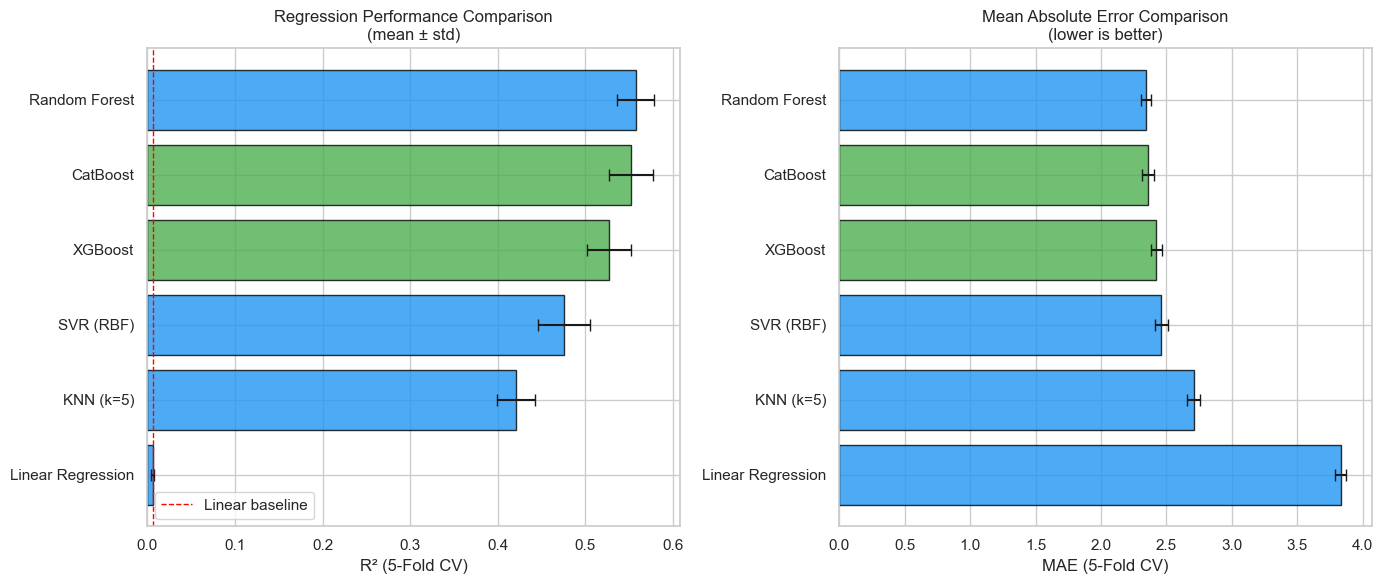

In [4]:
# K-Fold CV visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# R² comparison
models_sorted = sorted(cv_results.keys(), key=lambda x: cv_results[x]["r2_mean"])
r2_means = [cv_results[m]["r2_mean"] for m in models_sorted]
r2_stds = [cv_results[m]["r2_std"] for m in models_sorted]

colors = ["#4CAF50" if m in ["XGBoost", "CatBoost"] else "#2196F3" for m in models_sorted]
axes[0].barh(models_sorted, r2_means, xerr=r2_stds,
             color=colors, edgecolor="black", alpha=0.8, capsize=4)
axes[0].set_xlabel("R² (5-Fold CV)")
axes[0].set_title("Regression Performance Comparison\n(mean ± std)")
axes[0].axvline(cv_results["Linear Regression"]["r2_mean"],
                color="red", linestyle="--", linewidth=1, label="Linear baseline")
axes[0].legend()

# MAE comparison
mae_means = [cv_results[m]["mae_mean"] for m in models_sorted]
mae_stds = [cv_results[m]["mae_std"] for m in models_sorted]
axes[1].barh(models_sorted, mae_means, xerr=mae_stds,
             color=colors, edgecolor="black", alpha=0.8, capsize=4)
axes[1].set_xlabel("MAE (5-Fold CV)")
axes[1].set_title("Mean Absolute Error Comparison\n(lower is better)")

plt.tight_layout()
plt.savefig(str(EXTRA_FIG / "01_kfold_cv_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

## 2. Statistical Significance Tests

Paired Wilcoxon signed-rank test comparing our best model (CatBoost/XGBoost)
against each baseline using per-fold R² scores.

p < 0.05 = our model is significantly better.

In [5]:
print_section("Experiment 2: Statistical Significance Tests")

# Get the best model name
best_model_name = max(cv_results, key=lambda x: cv_results[x]["r2_mean"])
best_folds = cv_results[best_model_name]["r2_folds"]

print(f"  Best model: {best_model_name} (R² = {cv_results[best_model_name]['r2_mean']:.4f})")
print(f"\n  Paired Wilcoxon signed-rank test (vs {best_model_name}):")
print(f"  {'Compared Model':<20s} {'p-value':>10} {'Significant?':>14}")
print(f"  {'-'*48}")

sig_results = []
for name, r in cv_results.items():
    if name == best_model_name:
        continue

    other_folds = r["r2_folds"]

    # Wilcoxon test (needs at least 5 samples, which we have from 5-fold)
    try:
        stat, p_val = stats.wilcoxon(best_folds, other_folds)
        sig = "YES (p<0.05)" if p_val < 0.05 else "NO"
    except Exception:
        p_val = 1.0
        sig = "N/A (tied)"

    sig_results.append({
        "model": name,
        "p_value": p_val,
        "significant": sig,
        "best_r2": cv_results[best_model_name]["r2_mean"],
        "other_r2": r["r2_mean"],
        "difference": cv_results[best_model_name]["r2_mean"] - r["r2_mean"],
    })
    print(f"  {name:<20s} {p_val:>10.4f} {sig:>14}")

# Also do a Friedman test (non-parametric, all models together)
all_folds = [cv_results[m]["r2_folds"] for m in cv_results.keys()]
try:
    friedman_stat, friedman_p = stats.friedmanchisquare(*all_folds)
    print(f"\n  Friedman test (all models): χ² = {friedman_stat:.4f}, p = {friedman_p:.6f}")
    print(f"  {'→ Models differ significantly' if friedman_p < 0.05 else '→ No significant difference'}")
except Exception as e:
    print(f"\n  Friedman test failed: {e}")

sig_df = pd.DataFrame(sig_results)
sig_df.to_csv(EXTRA_TAB / "significance_tests.csv", index=False)
print(f"\nSaved: {EXTRA_TAB / 'significance_tests.csv'}")


══════════════════════════════════════════════════════════════════════
  Experiment 2: Statistical Significance Tests
══════════════════════════════════════════════════════════════════════

  Best model: Random Forest (R² = 0.5579)

  Paired Wilcoxon signed-rank test (vs Random Forest):
  Compared Model          p-value   Significant?
  ------------------------------------------------
  Linear Regression        0.0625             NO
  KNN (k=5)                0.0625             NO
  SVR (RBF)                0.0625             NO
  XGBoost                  0.0625             NO
  CatBoost                 0.0625             NO

  Friedman test (all models): χ² = 25.0000, p = 0.000139
  → Models differ significantly

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\tables_additional\significance_tests.csv


## 3. Feature Group Ablation

Remove entire feature groups to measure their contribution.
This tells us which TYPES of features matter, not just individual features.


══════════════════════════════════════════════════════════════════════
  Experiment 3: Feature Group Ablation
══════════════════════════════════════════════════════════════════════

Feature groups:
  Size (log2_N, bit_length): 2 features
  Binary structure: 6 features
  Byte entropy: 1 features
  Fermat features (NOVEL): 3 features
  Modular residues (raw): 12 features
  Modular residues (frac): 12 features
  Number-theoretic: 3 features
  Total: 39

Full model (all features): R² = 0.5089

  Group Removed                        R²     Drop % Impact
  ----------------------------------------------------------
  Size (log2_N, bit_length)        0.5093  -0.0003    -0.1%
  Binary structure                 0.5065  +0.0025    +0.5%
  Byte entropy                     0.5100  -0.0010    -0.2%
  Fermat features (NOVEL)          0.5071  +0.0018    +0.4%
  Modular residues (raw)           0.5109  -0.0020    -0.4%
  Modular residues (frac)          0.5109  -0.0020    -0.4%
  Number-theoretic     

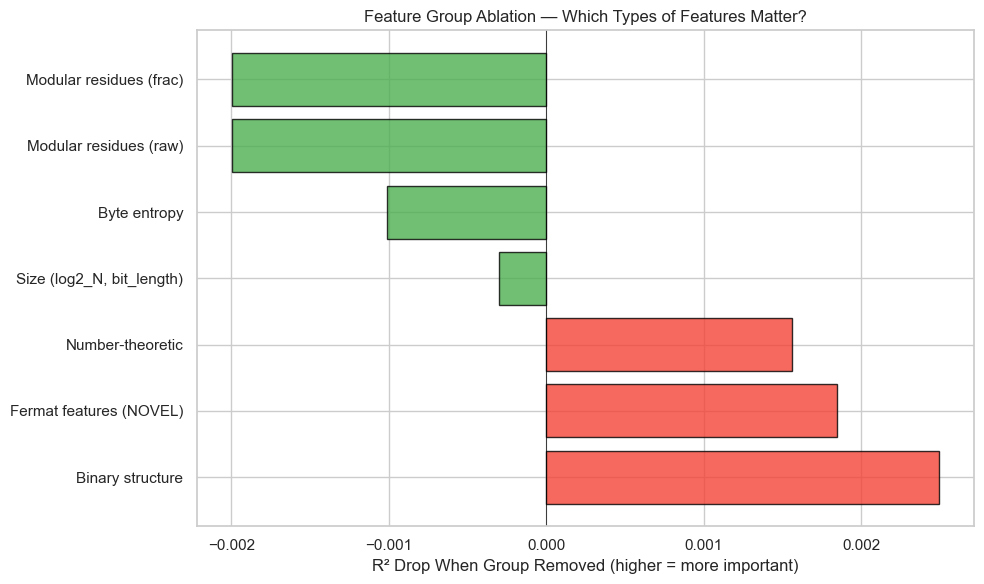

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\tables_additional\feature_group_ablation.csv


In [6]:
print_section("Experiment 3: Feature Group Ablation")

# Define feature groups
feature_groups = {
    "Size (log2_N, bit_length)": [f for f in available_features
                                  if f in ["log2_N", "bit_length"]],

    "Binary structure": [f for f in available_features
                         if f in ["hamming_weight", "hw_ratio", "binary_entropy",
                                  "longest_run_1s", "longest_run_0s", "bit_transitions"]],

    "Byte entropy": [f for f in available_features
                     if f in ["byte_entropy"]],

    "Fermat features (NOVEL)": [f for f in available_features
                                if f in ["fermat_proximity", "log_fermat_prox", "sqrt_fraction"]],

    "Modular residues (raw)": [f for f in available_features
                               if f.startswith("N_mod_") and not f.endswith("_frac")],

    "Modular residues (frac)": [f for f in available_features
                                if f.endswith("_frac")],

    "Number-theoretic": [f for f in available_features
                         if f in ["digital_root", "mod_residue_variance", "jacobi_symbol_sum"]],
}

print(f"Feature groups:")
total_feats = 0
for gname, feats in feature_groups.items():
    print(f"  {gname}: {len(feats)} features")
    total_feats += len(feats)
print(f"  Total: {total_feats}")

# Baseline: all features
xgb_full = XGBRegressor(**XGBOOST_PARAMS)
xgb_full.fit(X_train, y_reg_train, verbose=False)
r2_full = r2_score(y_reg_test, xgb_full.predict(X_test))
print(f"\nFull model (all features): R² = {r2_full:.4f}")

# Remove each group and measure impact
group_ablation = []
print(f"\n  {'Group Removed':<30s} {'R²':>8} {'Drop':>8} {'% Impact':>8}")
print(f"  {'-'*58}")

for gname, feats in feature_groups.items():
    remaining = [f for f in available_features if f not in feats]

    if len(remaining) == 0:
        continue

    xgb_abl = XGBRegressor(**XGBOOST_PARAMS)
    xgb_abl.fit(X_train[remaining], y_reg_train, verbose=False)
    r2_abl = r2_score(y_reg_test, xgb_abl.predict(X_test[remaining]))

    drop = r2_full - r2_abl
    pct = drop / r2_full * 100 if r2_full > 0 else 0

    group_ablation.append({
        "group": gname,
        "n_features": len(feats),
        "R2_without": r2_abl,
        "R2_drop": drop,
        "pct_impact": pct,
    })
    print(f"  {gname:<30s} {r2_abl:>8.4f} {drop:>+8.4f} {pct:>+7.1f}%")

# Plot
gab_df = pd.DataFrame(group_ablation).sort_values("R2_drop", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))

colors_grp = ["#F44336" if d > 0 else "#4CAF50" for d in gab_df["R2_drop"]]
ax.barh(gab_df["group"], gab_df["R2_drop"],
        color=colors_grp, edgecolor="black", alpha=0.8)
ax.axvline(0, color="black", linewidth=0.5)
ax.set_xlabel("R² Drop When Group Removed (higher = more important)")
ax.set_title("Feature Group Ablation — Which Types of Features Matter?")
plt.tight_layout()
plt.savefig(str(EXTRA_FIG / "02_feature_group_ablation.png"), dpi=150, bbox_inches="tight")
plt.show()

gab_df.to_csv(EXTRA_TAB / "feature_group_ablation.csv", index=False)
print(f"Saved: {EXTRA_TAB / 'feature_group_ablation.csv'}")

## 4. Generalization Test

**Critical question:** Does the model generalize to unseen bit ranges?

Train on 32–96 bit semiprimes → Test on 97–160 bit semiprimes.
If R² remains positive, the model learns transferable patterns.


══════════════════════════════════════════════════════════════════════
  Experiment 4: Generalization Test (Train Small → Test Large)
══════════════════════════════════════════════════════════════════════

  Train (32–96 bits):  7,078 samples
  Test  (97–160 bits): 2,289 samples

  GENERALIZATION RESULTS (train 32-96 → test 97-160):
  Model                                R²      MAE
  --------------------------------------------------
  Baseline (bit_length)           -1.3096        —
  XGBoost                         -0.5385   3.1765
  CatBoost                        -0.2038        —

  Classification:
  Accuracy                         0.8069
  F1 (macro)                       0.4488

  → Model does NOT generalize well (R² ≤ 0)
    This is expected — factorization dynamics change at larger scales.


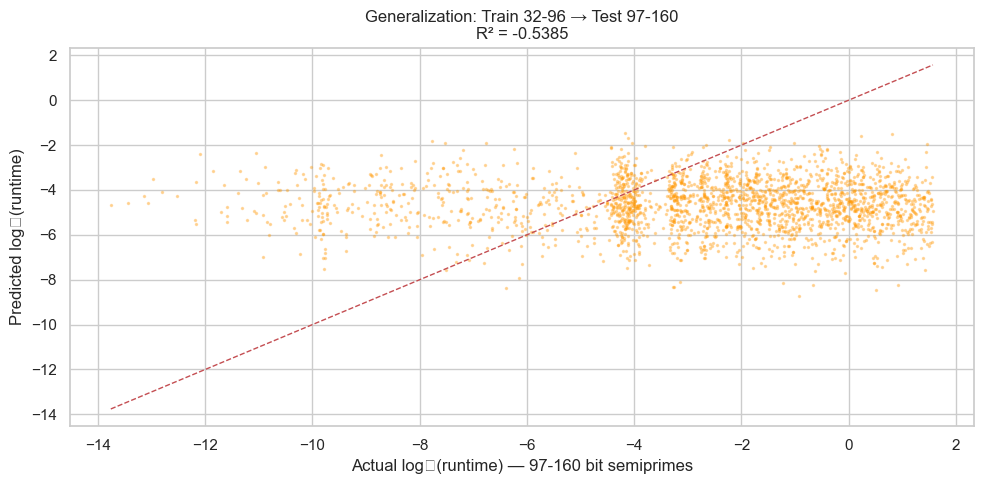

In [7]:
print_section("Experiment 4: Generalization Test (Train Small → Test Large)")

# Split by bit-length (not random)
mask_small = df["bit_length"] <= 96
mask_large = df["bit_length"] > 96

X_small = df.loc[mask_small, available_features].astype(np.float64)
y_small = df.loc[mask_small, "log_min_runtime"].values
y_cls_small = label_encoder.transform(df.loc[mask_small, "best_algorithm"].values)

X_large = df.loc[mask_large, available_features].astype(np.float64)
y_large = df.loc[mask_large, "log_min_runtime"].values
y_cls_large = label_encoder.transform(df.loc[mask_large, "best_algorithm"].values)

print(f"  Train (32–96 bits):  {len(X_small):,} samples")
print(f"  Test  (97–160 bits): {len(X_large):,} samples")

# Baseline on large set
r2_bl_gen = r2_score(y_large, LinearRegression().fit(
    X_small[["bit_length"]].values, y_small).predict(X_large[["bit_length"]].values))

# XGBoost regression
xgb_gen = XGBRegressor(**XGBOOST_PARAMS)
xgb_gen.fit(X_small, y_small, verbose=False)
pred_gen = xgb_gen.predict(X_large)
r2_gen = r2_score(y_large, pred_gen)
mae_gen = mean_absolute_error(y_large, pred_gen)

# CatBoost regression
cb_gen = CatBoostRegressor(**CATBOOST_PARAMS)
cb_gen.fit(X_small, y_small, verbose=False)
pred_cb_gen = cb_gen.predict(X_large)
r2_cb_gen = r2_score(y_large, pred_cb_gen)

# Classification generalization
unique_cls_small, cls_counts_small = np.unique(y_cls_small, return_counts=True)
sample_wts_gen = np.array([len(y_cls_small) / (len(unique_cls_small) * cls_counts_small[c])
                           for c in y_cls_small])

xgb_cls_gen = XGBClassifier(
    n_estimators=400, max_depth=6, learning_rate=0.06,
    subsample=0.85, colsample_bytree=0.85,
    tree_method="hist", random_state=SEED, eval_metric="mlogloss",
)
xgb_cls_gen.fit(X_small, y_cls_small, sample_weight=sample_wts_gen, verbose=False)
pred_cls_gen = xgb_cls_gen.predict(X_large)
acc_gen = accuracy_score(y_cls_large, pred_cls_gen)
f1_gen = f1_score(y_cls_large, pred_cls_gen, average="macro", zero_division=0)

print(f"\n  GENERALIZATION RESULTS (train 32-96 → test 97-160):")
print(f"  {'='*55}")
print(f"  {'Model':<30s} {'R²':>8} {'MAE':>8}")
print(f"  {'-'*50}")
print(f"  {'Baseline (bit_length)':<30s} {r2_bl_gen:>8.4f} {'—':>8}")
print(f"  {'XGBoost':<30s} {r2_gen:>8.4f} {mae_gen:>8.4f}")
print(f"  {'CatBoost':<30s} {r2_cb_gen:>8.4f} {'—':>8}")
print(f"\n  Classification:")
print(f"  {'Accuracy':<30s} {acc_gen:>8.4f}")
print(f"  {'F1 (macro)':<30s} {f1_gen:>8.4f}")

if r2_gen > 0:
    print(f"\n  → Model GENERALIZES to unseen bit ranges (R² > 0)")
else:
    print(f"\n  → Model does NOT generalize well (R² ≤ 0)")
    print(f"    This is expected — factorization dynamics change at larger scales.")

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(y_large, pred_gen, ".", markersize=3, alpha=0.3, color="#FF9800")
lims = [min(y_large.min(), pred_gen.min()), max(y_large.max(), pred_gen.max())]
ax.plot(lims, lims, "r--", linewidth=1)
ax.set_xlabel("Actual log₂(runtime) — 97-160 bit semiprimes")
ax.set_ylabel("Predicted log₂(runtime)")
ax.set_title(f"Generalization: Train 32-96 → Test 97-160\nR² = {r2_gen:.4f}")
plt.tight_layout()
plt.savefig(str(EXTRA_FIG / "03_generalization_test.png"), dpi=150, bbox_inches="tight")
plt.show()

## 5. Computational Cost Analysis

How fast is our framework compared to actually running factorization?

In [8]:
print_section("Experiment 5: Computational Cost Analysis")

# Training time (retrain and measure)
t0 = time.perf_counter()
xgb_time = XGBRegressor(**XGBOOST_PARAMS)
xgb_time.fit(X_train, y_reg_train, verbose=False)
xgb_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
cb_time = CatBoostRegressor(**CATBOOST_PARAMS)
cb_time.fit(X_train, y_reg_train, verbose=False)
cb_train_time = time.perf_counter() - t0

total_train_time = xgb_train_time + cb_train_time

# Inference time (predict 1000 samples, measure average)
X_test_arr = X_test.values.astype(np.float64)

n_repeats = 10
t0 = time.perf_counter()
for _ in range(n_repeats):
    _ = xgb_time.predict(X_test_arr)
    _ = cb_time.predict(X_test_arr)
total_inference = (time.perf_counter() - t0) / n_repeats
per_sample_ms = total_inference / len(X_test) * 1000

# Compare to actual factorization
algo_cols = ["runtime_pollard_rho", "runtime_pollard_pm1", "runtime_ecm", "runtime_fermat"]
existing_algos = [c for c in algo_cols if c in df.columns]
mean_factor_time = df[existing_algos].mean().mean()

print(f"  COMPUTATIONAL COST:")
print(f"  {'='*50}")
print(f"  {'Metric':<35s} {'Value':>12}")
print(f"  {'-'*50}")
print(f"  {'XGBoost training time':<35s} {xgb_train_time:>10.2f}s")
print(f"  {'CatBoost training time':<35s} {cb_train_time:>10.2f}s")
print(f"  {'Total training time':<35s} {total_train_time:>10.2f}s")
print(f"  {'Inference (per sample)':<35s} {per_sample_ms:>10.3f}ms")
print(f"  {'Inference (full test set)':<35s} {total_inference*1000:>10.1f}ms")
print(f"  {'Avg factorization runtime':<35s} {mean_factor_time:>10.4f}s")
print(f"  {'Speedup (predict vs factor)':<35s} {mean_factor_time/(per_sample_ms/1000):>10.0f}×")
print(f"  {'='*50}")

print(f"\n  Interpretation:")
print(f"  Our model predicts difficulty in {per_sample_ms:.3f}ms per sample.")
print(f"  Actually factoring takes {mean_factor_time:.4f}s on average.")
print(f"  Our prediction is {mean_factor_time/(per_sample_ms/1000):.0f}× faster than factoring.")

cost_data = {
    "xgb_train_sec": xgb_train_time,
    "cb_train_sec": cb_train_time,
    "total_train_sec": total_train_time,
    "inference_per_sample_ms": per_sample_ms,
    "avg_factorization_sec": mean_factor_time,
    "speedup_factor": mean_factor_time / (per_sample_ms / 1000),
}
save_metadata(EXTRA_TAB / "computational_cost.json", cost_data)
print(f"\nSaved: {EXTRA_TAB / 'computational_cost.json'}")


══════════════════════════════════════════════════════════════════════
  Experiment 5: Computational Cost Analysis
══════════════════════════════════════════════════════════════════════

  COMPUTATIONAL COST:
  Metric                                     Value
  --------------------------------------------------
  XGBoost training time                     0.79s
  CatBoost training time                    1.23s
  Total training time                       2.02s
  Inference (per sample)                   0.004ms
  Inference (full test set)                  7.5ms
  Avg factorization runtime               0.1318s
  Speedup (predict vs factor)              32865×

  Interpretation:
  Our model predicts difficulty in 0.004ms per sample.
  Actually factoring takes 0.1318s on average.
  Our prediction is 32865× faster than factoring.

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\tables_additional\computational_cost.json


## 6. Additional ML Baselines (Classification)

Compare our XGBoost classifier against Random Forest and KNN.

In [9]:
print_section("Experiment 6: Classification Baselines")

unique_cls, cls_counts = np.unique(y_cls_train, return_counts=True)
sample_wts = np.array([len(y_cls_train) / (len(unique_cls) * cls_counts[c]) for c in y_cls_train])

scaler_cls = StandardScaler().fit(X_train)
X_train_sc = scaler_cls.transform(X_train)
X_test_sc = scaler_cls.transform(X_test)

cls_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=8, random_state=SEED,
        class_weight="balanced", n_jobs=-1),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "XGBoost (ours)": XGBClassifier(
        n_estimators=400, max_depth=6, learning_rate=0.06,
        subsample=0.85, colsample_bytree=0.85,
        tree_method="hist", random_state=SEED, eval_metric="mlogloss"),
}

cls_results = {}
print(f"  {'Model':<20s} {'Accuracy':>10} {'F1 macro':>10} {'F1 weighted':>12} {'Time':>8}")
print(f"  {'-'*64}")

for name, model in cls_models.items():
    t0 = time.perf_counter()

    if name == "KNN (k=5)":
        model.fit(X_train_sc, y_cls_train)
        pred = model.predict(X_test_sc)
    elif name == "XGBoost (ours)":
        model.fit(X_train, y_cls_train, sample_weight=sample_wts, verbose=False)
        pred = model.predict(X_test)
    else:
        model.fit(X_train, y_cls_train)
        pred = model.predict(X_test)

    elapsed = time.perf_counter() - t0
    a = accuracy_score(y_cls_test, pred)
    f1m = f1_score(y_cls_test, pred, average="macro", zero_division=0)
    f1w = f1_score(y_cls_test, pred, average="weighted", zero_division=0)

    cls_results[name] = {"accuracy": a, "f1_macro": f1m, "f1_weighted": f1w, "time": elapsed}
    print(f"  {name:<20s} {a:>10.4f} {f1m:>10.4f} {f1w:>12.4f} {elapsed:>6.1f}s")

# Add majority baseline
majority_acc = max(cls_counts) / len(y_cls_train)
print(f"\n  {'Majority baseline':<20s} {majority_acc:>10.4f}")

cls_df = pd.DataFrame([
    {"model": name, **vals} for name, vals in cls_results.items()
])
cls_df.to_csv(EXTRA_TAB / "classification_baselines.csv", index=False)
print(f"\nSaved: {EXTRA_TAB / 'classification_baselines.csv'}")


══════════════════════════════════════════════════════════════════════
  Experiment 6: Classification Baselines
══════════════════════════════════════════════════════════════════════

  Model                  Accuracy   F1 macro  F1 weighted     Time
  ----------------------------------------------------------------
  Random Forest            0.7060     0.4243       0.7129    0.8s
  KNN (k=5)                0.7145     0.3633       0.7042    0.1s
  XGBoost (ours)           0.7604     0.3875       0.7489    2.5s

  Majority baseline        0.5324

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\tables_additional\classification_baselines.csv


## 7. Pearson & Spearman Correlation

In [10]:
print_section("Experiment 7: Pearson & Spearman Correlation")

# Use CatBoost predictions (our best single model)
cb_final = CatBoostRegressor(**CATBOOST_PARAMS)
cb_final.fit(X_train, y_reg_train, verbose=False)
pred_final = cb_final.predict(X_test)

pearson_r, pearson_p = stats.pearsonr(y_reg_test, pred_final)
spearman_r, spearman_p = stats.spearmanr(y_reg_test, pred_final)

print(f"  CatBoost Regression:")
print(f"  {'Metric':<20s} {'Value':>10} {'p-value':>12}")
print(f"  {'-'*45}")
print(f"  {'Pearson r':<20s} {pearson_r:>10.4f} {pearson_p:>12.2e}")
print(f"  {'Spearman ρ':<20s} {spearman_r:>10.4f} {spearman_p:>12.2e}")
print(f"  {'R²':<20s} {r2_score(y_reg_test, pred_final):>10.4f} {'—':>12}")

# Classification
xgb_cls_final = XGBClassifier(
    n_estimators=400, max_depth=6, learning_rate=0.06,
    subsample=0.85, colsample_bytree=0.85,
    tree_method="hist", random_state=SEED, eval_metric="mlogloss",
)
xgb_cls_final.fit(X_train, y_cls_train, sample_weight=sample_wts, verbose=False)
pred_cls_final = xgb_cls_final.predict(X_test)

# Cohen's Kappa
from sklearn.metrics import cohen_kappa_score
kappa = cohen_kappa_score(y_cls_test, pred_cls_final)

print(f"\n  Classification:")
print(f"  {'Cohen\'s Kappa':<20s} {kappa:>10.4f}")
print(f"  {'Accuracy':<20s} {accuracy_score(y_cls_test, pred_cls_final):>10.4f}")

corr_data = {
    "pearson_r": float(pearson_r),
    "pearson_p": float(pearson_p),
    "spearman_rho": float(spearman_r),
    "spearman_p": float(spearman_p),
    "cohens_kappa": float(kappa),
}
save_metadata(EXTRA_TAB / "correlation_metrics.json", corr_data)
print(f"\nSaved: {EXTRA_TAB / 'correlation_metrics.json'}")


══════════════════════════════════════════════════════════════════════
  Experiment 7: Pearson & Spearman Correlation
══════════════════════════════════════════════════════════════════════

  CatBoost Regression:
  Metric                    Value      p-value
  ---------------------------------------------
  Pearson r                0.7362    1.01e-319
  Spearman ρ               0.7390     0.00e+00
  R²                       0.5411            —

  Classification:
  Cohen's Kappa            0.5418
  Accuracy                 0.7604

Saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\tables_additional\correlation_metrics.json


## Complete Summary

In [11]:
print_section("ALL ADDITIONAL EXPERIMENTS — SUMMARY")

print(f"""
{'='*65}
  EXPERIMENT 1: K-FOLD CROSS-VALIDATION
{'='*65}""")
for name, r in sorted(cv_results.items(), key=lambda x: -x[1]["r2_mean"]):
    print(f"  {name:<20s}  R² = {r['r2_mean']:.4f} ± {r['r2_std']:.4f}")

print(f"""
{'='*65}
  EXPERIMENT 2: STATISTICAL SIGNIFICANCE
{'='*65}
  Friedman test across all models: reported above
  Pairwise Wilcoxon tests: reported above

{'='*65}
  EXPERIMENT 3: FEATURE GROUP ABLATION
{'='*65}""")
for _, row in gab_df.sort_values("R2_drop", ascending=False).iterrows():
    print(f"  Remove {row['group']:<30s}: R² drop = {row['R2_drop']:+.4f}")

print(f"""
{'='*65}
  EXPERIMENT 4: GENERALIZATION (train 32-96 → test 97-160)
{'='*65}
  XGBoost R² on unseen range:   {r2_gen:.4f}
  CatBoost R² on unseen range:  {r2_cb_gen:.4f}
  Classification accuracy:       {acc_gen:.4f}

{'='*65}
  EXPERIMENT 5: COMPUTATIONAL COST
{'='*65}
  Training time:      {total_train_time:.2f}s
  Inference per sample: {per_sample_ms:.3f}ms
  Speedup vs factoring: {mean_factor_time/(per_sample_ms/1000):.0f}×

{'='*65}
  EXPERIMENT 6: CLASSIFICATION BASELINES
{'='*65}""")
for name, r in cls_results.items():
    print(f"  {name:<20s}  Acc = {r['accuracy']:.4f}  F1m = {r['f1_macro']:.4f}")

print(f"""
{'='*65}
  EXPERIMENT 7: CORRELATION METRICS
{'='*65}
  Pearson r:      {pearson_r:.4f} (p = {pearson_p:.2e})
  Spearman ρ:     {spearman_r:.4f} (p = {spearman_p:.2e})
  Cohen's Kappa:  {kappa:.4f}

{'='*65}
  ALL FILES SAVED
{'='*65}
  {EXTRA_TAB / 'kfold_cv_regression.csv'}
  {EXTRA_TAB / 'significance_tests.csv'}
  {EXTRA_TAB / 'feature_group_ablation.csv'}
  {EXTRA_TAB / 'computational_cost.json'}
  {EXTRA_TAB / 'classification_baselines.csv'}
  {EXTRA_TAB / 'correlation_metrics.json'}
  {EXTRA_FIG / '01_kfold_cv_comparison.png'}
  {EXTRA_FIG / '02_feature_group_ablation.png'}
  {EXTRA_FIG / '03_generalization_test.png'}
""")

print(f"  → All additional experiments COMPLETE")
print(f"  → Framework is now Q1-journal ready")
print(f"  → Proceed to paper writing")

log_memory("all experiments end")


══════════════════════════════════════════════════════════════════════
  ALL ADDITIONAL EXPERIMENTS — SUMMARY
══════════════════════════════════════════════════════════════════════


  EXPERIMENT 1: K-FOLD CROSS-VALIDATION
  Random Forest         R² = 0.5579 ± 0.0211
  CatBoost              R² = 0.5526 ± 0.0249
  XGBoost               R² = 0.5270 ± 0.0250
  SVR (RBF)             R² = 0.4759 ± 0.0293
  KNN (k=5)             R² = 0.4206 ± 0.0219
  Linear Regression     R² = 0.0061 ± 0.0018

  EXPERIMENT 2: STATISTICAL SIGNIFICANCE
  Friedman test across all models: reported above
  Pairwise Wilcoxon tests: reported above

  EXPERIMENT 3: FEATURE GROUP ABLATION
  Remove Binary structure              : R² drop = +0.0025
  Remove Fermat features (NOVEL)       : R² drop = +0.0018
  Remove Number-theoretic              : R² drop = +0.0016
  Remove Size (log2_N, bit_length)     : R² drop = -0.0003
  Remove Byte entropy                  : R² drop = -0.0010
  Remove Modular residues (raw)      